# 3. Einstein time: 5-NN regression of $\log_{10} t_E$

In [1]:
import sys
sys.path.insert(0, "..")
import json
import numpy as np
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from tslearn.neighbors import KNeighborsTimeSeriesRegressor
from mldtw.simulate import make_dataset, centre

/tmp/claude-6022/-obs-ddehiwalage-don-microlensing-application/e5c22c67-9554-4daa-b0c8-8ca5c61a4549/scratchpad/venv/lib/python3.13/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)


In [2]:
X_train, y_train, p_train = make_dataset(150, seed=1, classes=[2, 3])
X_test, y_test, p_test = make_dataset(50, seed=2, classes=[2, 3])
t_train = np.log10([p["tE"] for p in p_train])
t_test = np.log10([p["tE"] for p in p_test])
Xc_train, Xc_test = centre(X_train), centre(X_test)

In [3]:
band = {"global_constraint": "sakoe_chiba", "sakoe_chiba_radius": 24}
metrics = {
    "Euclid": (False, "euclidean", {}),
    "Euclid, centred": (True, "euclidean", {}),
    "DTW": (False, "dtw", {}),
    "DTW band": (False, "dtw", band),
    "Centred + DTW": (True, "dtw", {}),
    "Centred + DTW band": (True, "dtw", band),
}
for g in [0.01, 0.1, 1, 10]:
    metrics[f"Centred soft-DTW, gamma={g}"] = (True, "softdtw", {"gamma": g})

In [4]:
def predict(centred, metric, params):
    A, B = (Xc_train, Xc_test) if centred else (X_train, X_test)
    knn = KNeighborsTimeSeriesRegressor(n_neighbors=5, metric=metric, metric_params=params)
    knn.fit(A, t_train)
    return knn.predict(B)

pred = dict(zip(metrics, Parallel(n_jobs=len(metrics))(delayed(predict)(*m) for m in metrics.values())))
rmse = {n: float(np.sqrt(np.mean((p - t_test) ** 2))) for n, p in pred.items()}
json.dump(rmse, open("../results/tE_rmse.json", "w"), indent=1)
rmse

/tmp/claude-6022/-obs-ddehiwalage-don-microlensing-application/e5c22c67-9554-4daa-b0c8-8ca5c61a4549/scratchpad/venv/lib/python3.13/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)
/tmp/claude-6022/-obs-ddehiwalage-don-microlensing-application/e5c22c67-9554-4daa-b0c8-8ca5c61a4549/scratchpad/venv/lib/python3.13/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)
/tmp/claude-6022/-obs-ddehiwalage-don-microlensing-application/e5c22c67-9554-4daa-b0c8-8ca5c61a4549/scratchpad/venv/lib/python3.13/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)
/tmp/claude-6022/-obs-ddehiwalage-don-microlensing-a

{'Euclid': 0.19692419923609833,
 'Euclid, centred': 0.12556080215102636,
 'DTW': 0.19394531141751228,
 'DTW band': 0.2058496140270373,
 'Centred + DTW': 0.1933426778027581,
 'Centred + DTW band': 0.15322582288644196,
 'Centred soft-DTW, gamma=0.01': 0.15852478220770425,
 'Centred soft-DTW, gamma=0.1': 0.14465636881622976,
 'Centred soft-DTW, gamma=1': 0.14658353459212106,
 'Centred soft-DTW, gamma=10': 0.17610392449354234}

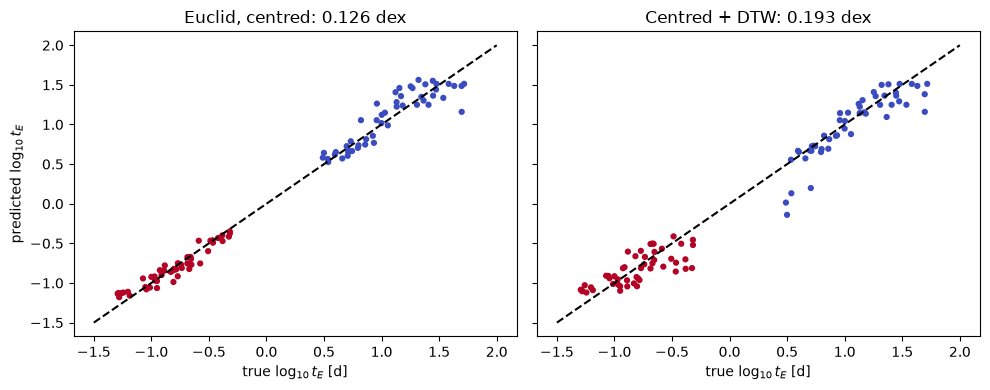

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, n in zip(axes, ["Euclid, centred", "Centred + DTW"]):
    ax.scatter(t_test, pred[n], c=y_test, s=12, cmap="coolwarm")
    ax.plot([-1.5, 2], [-1.5, 2], "k--")
    ax.set_title(f"{n}: {rmse[n]:.3f} dex")
    ax.set_xlabel("true $\\log_{10} t_E$ [d]")
axes[0].set_ylabel("predicted $\\log_{10} t_E$")
plt.tight_layout()
plt.savefig("../figures/tE_recovery.png", dpi=150)